# 04 — Agrupamentos: que "tipos" de cartório existem em MG, e qual é o cliente do seguro?

**Para que serve este notebook.** Separar as serventias de MG em **grupos parecidos entre si** (pela receita, pelos empregados, pelo número de atribuições e pela situação), sem dizer antes quais grupos procurar, e descrever cada um. A pergunta final é **qual grupo é o mercado-alvo do seguro-garantia** do Prov. 227, e por quê.

**Lembrete do mercado.** O Prov. 227 obriga as serventias **providas** que **não são Classe 1** (receita acima de R$ 300 mil por semestre) a garantir o passivo trabalhista. O **déficit** é a parte do passivo que o titular não consegue cobrir com bens; é ela que o seguro garante (número oficial nº 7: R$ 36,9 mi). Este notebook **não muda** nenhum dos 10 números.

**Termos usados** (explicados onde aparecem pela primeira vez): agrupamento, escala log, padronização, k-means, centro do grupo, inércia, cotovelo, silhueta, agrupamento hierárquico de Ward, índice de Rand ajustado.

**Dados:** banco do pipeline (carga de 19/10/2026: CNJ/Justiça Aberta, IBGE), cenário **base**, regra de classe **v2**. Parâmetros em `config/analise.yaml` (`grupos`). Os gráficos também vão em PNG para `docs/qa/analises/`.

In [1]:
import sys
import textwrap
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import adjusted_rand_score

from src.analise import config, dados, enquadramento, graficos as g, grupos as gr
from src.notebooks import conectar

g.estilo()
semente = config()["semente"]
con = conectar()
sv = dados.serventias(con)
x = gr.matriz(sv)
z = gr.padronizar(x)
fora = sv[~sv.cns.isin(x.index)]
print(f"{g.num(len(sv))} serventias ativas; {g.num(len(x))} entram no agrupamento; {g.num(len(fora))} ficam fora "
      f"(sem receita de 2025 > 0 ou sem CLT informado), com {g.reais(fora.valor_descoberto.sum())} do déficit de "
      f"{g.reais(sv.valor_descoberto.sum())}.")
print("Quem fica fora, por classe e situação:", fora.groupby(["classe", "situacao"]).size().to_dict(),
      f"| sem CLT informado: {g.num(fora.clt.isna().sum())}")
display(g.tabela(x.describe().T.reset_index(names="variável")[["variável", "mean", "std", "min", "50%", "max"]],
                 {c: "num2" for c in ["mean", "std", "min", "50%", "max"]})
        .rename(columns={"mean": "média", "std": "desvio padrão", "min": "mínimo", "50%": "mediana", "max": "máximo"}))

2.525 serventias ativas; 2.444 entram no agrupamento; 81 ficam fora (sem receita de 2025 > 0 ou sem CLT informado), com R$ 535,6 mil do déficit de R$ 36,9 mi.
Quem fica fora, por classe e situação: {('1', 'provida'): 1, ('1', 'vaga'): 2, ('indeterminada', 'outras'): 3, ('indeterminada', 'provida'): 27, ('indeterminada', 'vaga'): 48} | sem CLT informado: 4


,variável,média,desvio padrão,mínimo,mediana,máximo
0,log_receita,"5,49","0,74","2,77","5,51","7,73"
1,log_clt,"0,57","0,37","0,00","0,48","2,04"
2,n_atribuicoes,"1,70","0,62","1,00","2,00","5,00"
3,provida,"0,67","0,47","0,00","1,00","1,00"
4,vaga,"0,32","0,47","0,00","0,00","1,00"


**Quem fica fora.** As 78 serventias de classe indeterminada (sem receita válida em 2025; notebook 01) e 3 de Classe 1 sem CLT informado (a 4ª sem CLT também é indeterminada) não têm como entrar na conta de distância. Juntas, têm só R$ 0,5 mi do déficit de R$ 36,9 mi (1,5%).

## 1. As variáveis e a padronização

**A pergunta.** Como medir se dois cartórios são "parecidos"?

**O método.** Cada serventia vira um ponto com 5 coordenadas:
- **log10 da receita de referência de 2025** (R$ por semestre). Em log, R$ 100 mil → 5 e R$ 1 milhão → 6: um cartório 10 vezes maior fica a 1 passo, não a 900 mil. Sem o log, os poucos cartórios gigantes dominariam a distância (notebook 02: cauda longa);
- **log10(1 + empregados CLT)**: o "1 +" deixa entrar quem tem zero CLT (log10(1) = 0);
- **número de atribuições** (1 a 5);
- **situação**, em duas colunas 0/1: provida e vaga (as "outras", sob intervenção ou em diligência, ficam com 0 nas duas).

Depois, cada coluna é **padronizada**: (valor − média) ÷ desvio padrão. Exemplo: se a média do log da receita é 5,5 e o desvio padrão é 0,6, uma serventia com log 6,1 fica com (6,1 − 5,5) ÷ 0,6 = +1, ou seja, "1 desvio acima da média". Assim, todas as colunas pesam igual na distância, e uma variável medida em números grandes não engole as outras.

A distância entre dois cartórios é a **distância em linha reta** (euclidiana) entre os dois pontos padronizados.

**Limitações.** A situação, padronizada, pesa tanto quanto a receita: os grupos tendem a separar providas e vagas, o que é desejado aqui (as vagas ficam fora do universo), mas é uma escolha. Não houve teste de métodos para este notebook (os testes T1 a T7 cobrem os notebooks 05 a 08); os métodos são os do `plano_mineracao.md`.

## 2. Quantos grupos? A silhueta e o cotovelo

**A pergunta.** Em quantos grupos (k) os cartórios se separam melhor?

**O método.**
- O **k-means** escolhe k centros e põe cada serventia no grupo do centro mais próximo; depois move cada centro para a média do seu grupo e repete até parar de mudar. Como o começo é sorteado, ele recomeça 20 vezes (semente fixa) e fica com a melhor rodada.
- A **inércia** é a soma das distâncias (ao quadrado) de cada serventia ao centro do seu grupo. Ela sempre cai quando k sobe; o **cotovelo** é o k a partir do qual ela passa a cair pouco.
- A **silhueta** mede, para cada serventia, se ela está mais perto do próprio grupo do que do grupo vizinho: (b − a) ÷ o maior dos dois, em que a = distância média aos colegas de grupo e b = distância média ao grupo vizinho mais próximo. Vai de −1 (no grupo errado) a +1 (bem separada). Exemplo: a = 1 e b = 3 dá (3 − 1) ÷ 3 = 0,67. A média de todas as serventias diz quão bem separados estão os grupos.

**Regra de escolha (fixada antes de olhar os grupos):** o k de 2 a 8 com a **maior silhueta média**; o cotovelo serve de conferência.

,k,silhueta,inercia,silhueta_ward,rand_ajustado_kmeans_ward
0,2,"0,50",6.352,"0,49","0,89"
1,3,"0,45",4.483,"0,44","0,93"
2,4,"0,46",3.455,"0,45","0,94"
3,5,"0,49",2.809,"0,48","0,92"
4,6,"0,50",2.313,"0,50","0,93"
5,7,"0,45",1.949,"0,44","0,89"
6,8,"0,44",1.683,"0,42","0,84"


k escolhido (maior silhueta): 6.


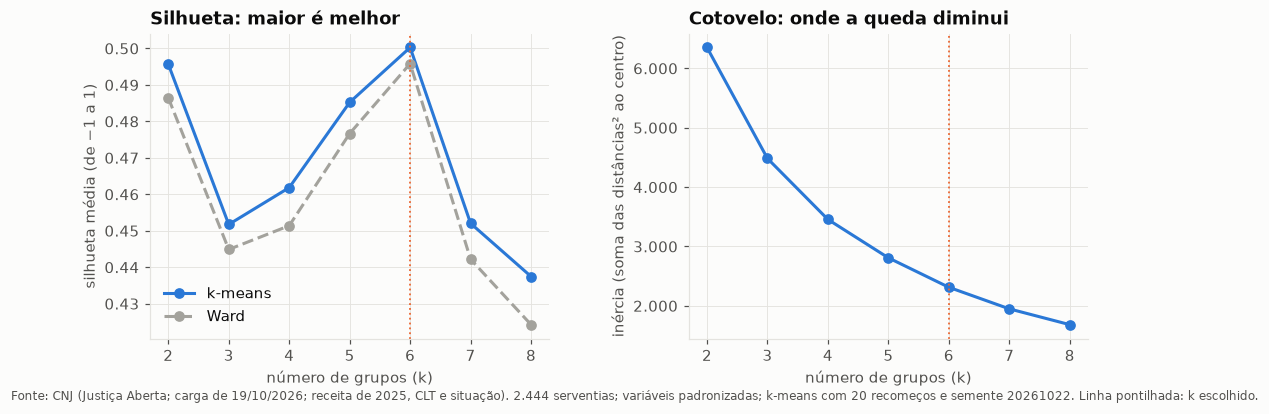

In [2]:
escolha = gr.escolha_k(z)
k = int(escolha.loc[escolha.silhueta.idxmax(), "k"])
display(g.tabela(escolha, {"k": "int", "silhueta": "num2", "inercia": "int", "silhueta_ward": "num2",
                           "rand_ajustado_kmeans_ward": "num2"}))
print(f"k escolhido (maior silhueta): {k}.")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
fig.subplots_adjust(wspace=0.35)
a1.plot(escolha.k, escolha.silhueta, marker="o", color=g.CORES[0], label="k-means")
a1.plot(escolha.k, escolha.silhueta_ward, marker="o", color=g.CINZA, linestyle="--", label="Ward")
a1.axvline(k, color=g.CORES[1], linewidth=1.2, linestyle=":")
a1.set_xlabel("número de grupos (k)")
a1.set_ylabel("silhueta média (de −1 a 1)")
a1.set_title("Silhueta: maior é melhor")
a1.legend()
a2.plot(escolha.k, escolha.inercia, marker="o", color=g.CORES[0])
a2.axvline(k, color=g.CORES[1], linewidth=1.2, linestyle=":")
g.eixo_num(a2)
a2.set_xlabel("número de grupos (k)")
a2.set_ylabel("inércia (soma das distâncias² ao centro)")
a2.set_title("Cotovelo: onde a queda diminui")
g.nota(fig, f"Fonte: CNJ (Justiça Aberta; carga de 19/10/2026; receita de 2025, CLT e situação). {g.num(len(x))} serventias; "
            f"variáveis padronizadas; k-means com 20 recomeços e semente {semente}. Linha pontilhada: k escolhido.")
g.salvar(fig, "04_escolha_k_silhueta_cotovelo")
plt.show()

**Como ler.** À esquerda, a silhueta de cada k (azul: k-means; cinza: Ward); à direita, a inércia.

**O que encontramos.** A silhueta é alta para qualquer k (0,44 a 0,50, uma separação razoável a boa) e tem dois picos: **k = 2** (0,496, que só separa vagas de providas) e **k = 6** (0,500, o maior). A regra escolhe **k = 6**. O cotovelo não é nítido: a inércia cai cerca de 30% de 2 para 3 grupos e depois de 14% a 23% a cada grupo a mais; entre 5 e 7 a curva já está achatando, o que é coerente com k = 6. O Ward dá silhuetas quase iguais, com o mesmo pico em 6.

**Limitações.** A diferença de silhueta entre k = 6 e k = 2 é pequena (0,005): os dois agrupamentos são bons, e o de 6 foi escolhido por ser o maior e por dizer mais sobre o mercado.

## 3. Os grupos

**A pergunta.** Como é cada grupo?

**O método.** k-means com k = 6. Os grupos são numerados de 1 a 6 pela **receita mediana**, da menor para a maior (o número que o k-means dá é arbitrário). O perfil de cada grupo soma os resultados do modelo do painel: obrigadas (soma dos pesos do universo), passivo, déficit esperado e serventias com déficit esperado (somas das probabilidades).

In [3]:
rotulos = gr.ordenar_por_receita(gr.kmeans(z, k), x.log_receita)
grupo = pd.Series(rotulos, index=x.index, name="grupo")
perfil = gr.perfil(sv, grupo)

# nomes pelo perfil; as conferências param o notebook se uma nova carga mudar o perfil que o nome descreve
nomes = {1: "vagas pequenas", 2: "providas pequenas (Notas e RCPN)", 3: "providas médias de uma atribuição",
         4: "registro completo (RI, RTD e RCPJ)", 5: "vagas grandes", 6: "providas grandes"}
assert perfil.loc[1, "pct_vagas"] > 0.9 and perfil.loc[5, "pct_vagas"] > 0.9
assert perfil.loc[[2, 3, 6], "pct_vagas"].max() < 0.05 and perfil.loc[4, "pct_ri"] > 0.5
assert perfil.loc[3, "atribuicoes_medianas"] == 1 and perfil.receita_mediana.idxmax() == 6
perfil.insert(0, "nome", [nomes[i] for i in perfil.index])
display(g.tabela(perfil.reset_index()[["grupo", "nome", "serventias", "receita_mediana", "clt_mediano",
                                       "atribuicoes_medianas", "pct_vagas", "obrigadas", "pct_obrigadas", "passivo",
                                       "com_deficit", "deficit", "pct_deficit_mg", "deficit_por_obrigada"]],
                 {"serventias": "int", "receita_mediana": "reais", "clt_mediano": "num1", "atribuicoes_medianas": "int",
                  "pct_vagas": "pct", "obrigadas": "num1", "pct_obrigadas": "pct", "passivo": "reais",
                  "com_deficit": "num1", "deficit": "reais", "pct_deficit_mg": "pct", "deficit_por_obrigada": "reais"}))
atrib = perfil[["nome"] + [f"pct_{a}" for a in dados.ATRIBUICOES]]
display(g.tabela(atrib.rename(columns={f"pct_{a}": dados.NOMES_ATRIBUICOES[a] for a in dados.ATRIBUICOES})
                 .reset_index(), {dados.NOMES_ATRIBUICOES[a]: "pct" for a in dados.ATRIBUICOES}))

,grupo,nome,serventias,receita_mediana,clt_mediano,atribuicoes_medianas,pct_vagas,obrigadas,pct_obrigadas,passivo,com_deficit,deficit,pct_deficit_mg,deficit_por_obrigada
0,1,vagas pequenas,688,"R$ 67,1 mil","1,0",2,"99,6%","0,0","0,0%","R$ 15,7 mi","0,0",R$ 0,"0,0%",—
1,2,providas pequenas (Notas e RCPN),634,"R$ 285,1 mil","2,0",2,"0,0%","300,0","47,3%","R$ 31,5 mi","146,0","R$ 5,3 mi","14,5%","R$ 17,8 mil"
2,3,providas médias de uma atribuição,578,"R$ 453,5 mil","3,0",1,"0,0%","383,0","66,3%","R$ 36,9 mi","183,6","R$ 7,2 mi","19,5%","R$ 18,8 mil"
3,4,"registro completo (RI, RTD e RCPJ)",188,"R$ 1,4 mi","6,0",3,"2,7%","159,0","84,6%","R$ 26,2 mi","63,7","R$ 3,7 mi","10,0%","R$ 23,1 mil"
4,5,vagas grandes,91,"R$ 1,4 mi","7,0",1,"98,9%","0,0","0,0%","R$ 32,2 mi","0,0",R$ 0,"0,0%",—
5,6,providas grandes,265,"R$ 3,3 mi","13,0",1,"0,0%","261,0","98,5%","R$ 164,4 mi","83,9","R$ 20,1 mi","54,6%","R$ 77,1 mil"


,grupo,nome,Notas,Registro civil (RCPN),Registro de imóveis (RI),Títulos e documentos (RTD),Pessoas jurídicas (RCPJ),Protesto
0,1,vagas pequenas,"92,7%","96,1%","0,9%","3,1%","3,1%","0,9%"
1,2,providas pequenas (Notas e RCPN),"82,3%","76,3%","0,5%","16,2%","16,4%","8,5%"
2,3,providas médias de uma atribuição,"46,0%","22,5%","5,0%","0,0%","0,0%","26,5%"
3,4,"registro completo (RI, RTD e RCPJ)","23,9%","23,4%","75,5%","77,7%","77,7%","23,4%"
4,5,vagas grandes,"38,5%","27,5%","24,2%","1,1%","1,1%","16,5%"
5,6,providas grandes,"40,0%","14,7%","42,3%","1,5%","1,9%","9,4%"


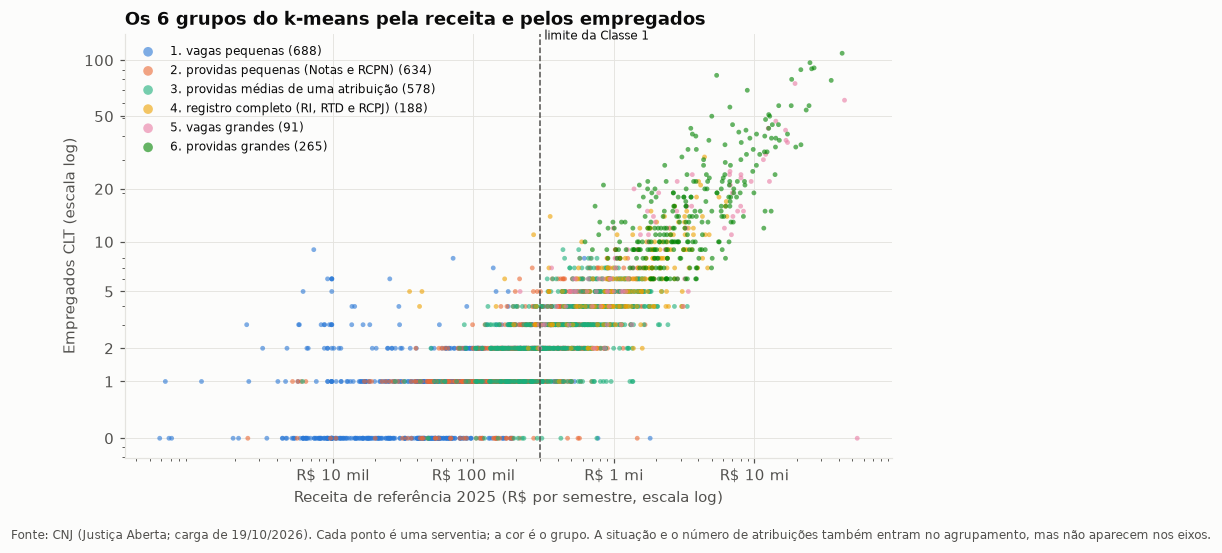

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
s = sv.set_index("cns").loc[x.index]
for i, cor in zip(range(1, k + 1), g.CORES):
    m = grupo == i
    ax.scatter(s.receita_ref[m], s.clt[m] + 1, s=10, alpha=0.6, color=cor, edgecolors="none",
               label=f"{i}. {nomes[i]} ({g.num(m.sum())})")
ax.set_xscale("log")
ax.set_yscale("log")
limite = enquadramento.limites_classe()[0]
ax.axvline(limite, color=g.TEXTO_2, linestyle="--", linewidth=1)
ax.text(limite, 130, " limite da Classe 1", fontsize=8, color=g.TEXTO)
ax.set_xticks([1e4, 1e5, 1e6, 1e7], [g.reais(v, 0) for v in [1e4, 1e5, 1e6, 1e7]])
ax.set_yticks([1, 2, 3, 6, 11, 21, 51, 101], ["0", "1", "2", "5", "10", "20", "50", "100"])
ax.set_xlabel("Receita de referência 2025 (R$ por semestre, escala log)")
ax.set_ylabel("Empregados CLT (escala log)")
ax.legend(fontsize=8, loc="upper left", markerscale=2)
ax.set_title("Os 6 grupos do k-means pela receita e pelos empregados")
g.nota(fig, "Fonte: CNJ (Justiça Aberta; carga de 19/10/2026). Cada ponto é uma serventia; a cor é o grupo. A situação e o "
            "número de atribuições também entram no agrupamento, mas não aparecem nos eixos.")
g.salvar(fig, "04_grupos_receita_clt")
plt.show()

**Como ler.** A primeira tabela traz o perfil de cada grupo; a segunda, a % de serventias de cada grupo com cada atribuição. No gráfico, cada ponto é uma serventia; grupos que se sobrepõem nos eixos se separam pela situação ou pelo número de atribuições.

**Os 6 grupos.**
1. **Vagas pequenas** (688): quase todas vagas (99,6%), receita típica de R$ 67 mil por semestre e 1 CLT, Notas e RCPN de distrito. Fora do universo.
2. **Providas pequenas, de Notas e RCPN** (634): receita típica de R$ 285 mil, **logo abaixo do limite** da Classe 1, e 2 CLT. Metade (47%) é obrigada.
3. **Providas médias de uma atribuição** (578): receita de R$ 454 mil, 3 CLT, uma atribuição só (Notas, RCPN ou Protesto). Dois terços (66%) são obrigadas.
4. **Registro completo** (188): RI, RTD e RCPJ juntos (cerca de 3 em 4), receita de R$ 1,4 mi e 6 CLT; 85% obrigadas.
5. **Vagas grandes** (91): 99% vagas, mas com receita de R$ 1,4 mi e 7 CLT. Fora do universo **hoje**.
6. **Providas grandes** (265): receita de R$ 3,3 mi, 13 CLT; **98,5% obrigadas** (quase todas Classe 3).

**Limitações.** Os grupos são uma simplificação: muitas serventias ficam na fronteira entre dois grupos. Os nomes descrevem o perfil típico, não todas as serventias do grupo.

## 4. Comparação com o agrupamento hierárquico (Ward)

**A pergunta.** Os grupos são do método ou dos dados? Outro método chega aos mesmos grupos?

**O método.**
- O **agrupamento hierárquico de Ward** começa com cada serventia sozinha e, a cada passo, junta os dois grupos cuja união aumenta menos a inércia, até sobrarem k grupos. Não tem sorteio.
- O **índice de Rand ajustado** (ARI) compara dois agrupamentos: olha todos os pares de serventias e conta em quantos os dois métodos concordam ("juntas" ou "separadas"), descontando a concordância esperada por acaso. 1 = mesmos grupos; 0 = concordância de acaso. Exemplo: se os dois métodos põem as mesmas serventias juntas, menos um punhado trocado de grupo, o ARI fica perto de 0,9.
- Também refazemos o k-means com outras 3 sementes, para ver se o sorteio inicial muda os grupos.

In [5]:
rotulos_ward = gr.ordenar_por_receita(gr.ward(z, k), x.log_receita)
ari = adjusted_rand_score(rotulos, rotulos_ward)
print(f"Índice de Rand ajustado, k-means × Ward (k = {k}): {g.num(ari, 3)}.")
cruz = pd.crosstab(pd.Series(rotulos, name="k-means"), pd.Series(rotulos_ward, name="Ward"))
display(cruz)
outras = {sd: adjusted_rand_score(rotulos, gr.kmeans(z, k, semente=sd)) for sd in [1, 2, 3]}
print("k-means com outras sementes × semente do projeto (ARI): "
      + "; ".join(f"semente {sd}: {g.num(v, 3)}" for sd, v in outras.items()))

Índice de Rand ajustado, k-means × Ward (k = 6): 0,935.


Ward,1,2,3,4,5,6
k-means,,,,,,
1,685,3,0,0,0,0
2,0,631,0,3,0,0
3,0,5,573,0,0,0
4,5,2,0,181,0,0
5,9,1,0,0,81,0
6,0,26,23,0,3,213


k-means com outras sementes × semente do projeto (ARI): semente 1: 1,000; semente 2: 1,000; semente 3: 1,000


**Como ler.** Na tabela cruzada, cada linha é um grupo do k-means e cada coluna um grupo do Ward; os números fora da diagonal são as serventias em que os métodos discordam.

**O que encontramos.** O ARI é de **0,93**: os dois métodos chegam quase aos mesmos grupos. A maior discordância está no grupo 6 (providas grandes): o Ward manda cerca de 50 delas para os grupos 2 e 3, ou seja, a fronteira entre "média" e "grande" é a menos nítida. Com outras sementes, o k-means dá exatamente os mesmos grupos (ARI = 1).

**O que significa.** Os grupos vêm dos dados, não de um detalhe do método. A fronteira entre providas médias e grandes é a parte mais "mole".

**Limitações.** Os dois métodos usam as mesmas variáveis padronizadas e a mesma ideia de distância; concordar entre si não prova que essas são as variáveis certas, só que o resultado não é acaso do sorteio nem do algoritmo.

## 5. Qual grupo é o mercado-alvo do seguro?

**A pergunta.** Em qual grupo está o dinheiro que o seguro garantiria?

**O método.** O seguro cobre o **déficit**: a parte do passivo das obrigadas que o titular não cobre com bens. O **grupo-alvo** é o que concentra a maior parte do déficit esperado de MG (regra fixada em `grupos.grupo_alvo`). Comparamos, para cada grupo, a parte das serventias, a parte das obrigadas e a parte do déficit.

Grupo-alvo: 6. providas grandes — 10,8% das serventias agrupadas, 23,7% das obrigadas e 54,6% do déficit de MG (R$ 20,1 mi); déficit por obrigada de R$ 77,1 mil, contra R$ 19,3 mil nos outros grupos.


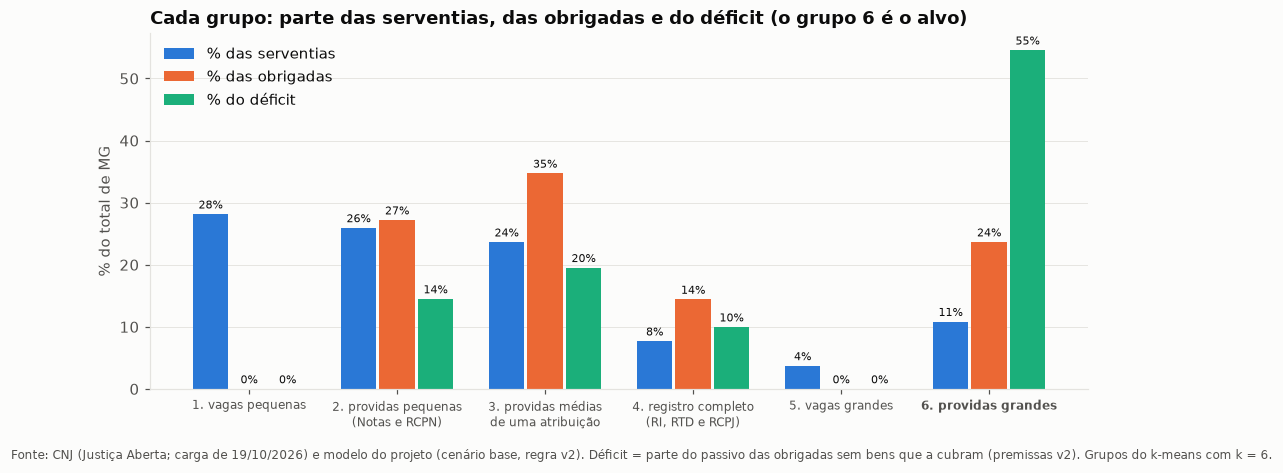

In [6]:
alvo = gr.grupo_alvo(perfil)
part = pd.DataFrame({"serventias": perfil.serventias / perfil.serventias.sum(),
                     "obrigadas": perfil.obrigadas / perfil.obrigadas.sum(),
                     "déficit": perfil.pct_deficit_mg})
print(f"Grupo-alvo: {alvo}. {nomes[alvo]} — {g.pct(part.loc[alvo, 'serventias'])} das serventias agrupadas, "
      f"{g.pct(part.loc[alvo, 'obrigadas'])} das obrigadas e {g.pct(part.loc[alvo, 'déficit'])} do déficit de MG "
      f"({g.reais(perfil.loc[alvo, 'deficit'])}); déficit por obrigada de {g.reais(perfil.loc[alvo, 'deficit_por_obrigada'])}, "
      f"contra {g.reais(perfil.drop(alvo).deficit.sum() / perfil.drop(alvo).obrigadas.sum())} nos outros grupos.")

fig, ax = plt.subplots(figsize=(11, 4.2))
xg = np.arange(k)
for j, (col, cor) in enumerate(zip(part.columns, g.CORES)):
    b = ax.bar(xg + (j - 1) * 0.26, 100 * part[col], width=0.24, color=cor, label=f"% das {col}" if col != "déficit" else "% do déficit")
    ax.bar_label(b, [g.pct(v, 0) for v in part[col]], fontsize=7, padding=2, color=g.TEXTO)
ax.set_xticks(xg, [textwrap.fill(f"{i}. {nomes[i]}", 20) for i in perfil.index], fontsize=8)
ax.get_xticklabels()[alvo - 1].set_fontweight("bold")
ax.set_ylabel("% do total de MG")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.set_title("Cada grupo: parte das serventias, das obrigadas e do déficit (o grupo 6 é o alvo)")
g.nota(fig, "Fonte: CNJ (Justiça Aberta; carga de 19/10/2026) e modelo do projeto (cenário base, regra v2). Déficit = parte "
            "do passivo das obrigadas sem bens que a cubram (premissas v2). Grupos do k-means com k = 6.")
g.salvar(fig, "04_grupos_participacao_deficit")
plt.show()

**Como ler.** Para cada grupo, a barra azul é a % das serventias; a laranja, a % das obrigadas; a verde, a % do déficit.

**O que encontramos.**
- O **grupo 6 (providas grandes)** é só **11%** das serventias e 24% das obrigadas, mas tem **55% do déficit** de MG (R$ 20,1 mi). O déficit por obrigada é de **R$ 77 mil**, cerca de 4 vezes o dos outros grupos.
- Os grupos 2 e 3 (providas pequenas e médias) somam 62% das obrigadas e 34% do déficit: muitos contratos pequenos (cerca de R$ 18 a 19 mil de déficit por obrigada).
- O grupo 4 (registro completo) tem 10% do déficit.
- Os grupos 1 e 5 (vagas) não têm déficit, porque estão fora do universo. Mas o **grupo 5 (vagas grandes)** tem R$ 32 mi de passivo: quando essas 91 serventias forem providas por concurso, quase todas entram no universo.

**Qual é o mercado-alvo e por quê.** O **grupo 6**: poucas serventias (265), quase todas obrigadas, com o maior passivo e o maior déficit por contrato. Para uma seguradora, é onde o prêmio se concentra com o menor custo de venda (poucos contratos grandes). Os grupos 2 e 3 são um mercado **de varejo**: muitos contratos pequenos, que só valem com venda simples e barata. O grupo 5 é o **mercado futuro**.

**Limitações.** O déficit vem das premissas de patrimônio do titular (`fonte: suposição`, D-016), que variam por classe: a parte de cada grupo no déficit herda essas suposições. A conta abaixo refaz a parte de cada grupo no déficit com as premissas no **mínimo** e no **máximo** (mesmos grupos; muda só o déficit de cada serventia).

In [7]:
sens = pd.DataFrame({nivel: gr.perfil(dados.serventias(con, nivel=nivel), grupo).pct_deficit_mg
                     for nivel in ["min", "base", "max"]})
sens.insert(0, "nome", [nomes[i] for i in sens.index])
display(g.tabela(sens.reset_index(), {"min": "pct", "base": "pct", "max": "pct"})
        .rename(columns={"min": "% do déficit (premissas no mínimo)", "base": "% (base)", "max": "% (máximo)"}))

,grupo,nome,% do déficit (premissas no mínimo),% (base),% (máximo)
0,1,vagas pequenas,"0,0%","0,0%","0,0%"
1,2,providas pequenas (Notas e RCPN),"17,5%","14,5%","12,4%"
2,3,providas médias de uma atribuição,"23,5%","19,5%","16,6%"
3,4,"registro completo (RI, RTD e RCPJ)","10,3%","10,0%","10,4%"
4,5,vagas grandes,"0,0%","0,0%","0,1%"
5,6,providas grandes,"48,6%","54,6%","58,6%"


**O que encontramos.** O grupo 6 continua sendo o que tem a maior parte do déficit nos três níveis: **49%** com as premissas no mínimo, 55% na base e **59%** no máximo. A escolha do grupo-alvo não depende do nível das premissas; o que muda é o tamanho da fatia dele.

## 6. Desenho da tabela `gold.analise_grupos`

**O que é.** A tabela que o painel vai ler (gerada pelo pipeline na Etapa 2, pela função `grupos.tabela_grupos`, que tem teste). Uma linha por serventia agrupada, para o painel poder filtrar o mapa e as tabelas por grupo; o perfil de cada grupo sai de `grupos.perfil` sobre ela.

| Coluna | Tipo | O que é |
|---|---|---|
| `cns` | texto | identificador da serventia no CNJ |
| `grupo` | inteiro | 1 a k, pela receita mediana do grupo |
| `nome_grupo` | texto | nome do perfil (por exemplo, "providas grandes") |
| `grupo_alvo` | lógico | verdadeiro no grupo com a maior parte do déficit |
| `k` | inteiro | número de grupos (escolhido pela silhueta) |
| `semente` | inteiro | semente do k-means (de `config/analise.yaml`) |

No pipeline, cada linha leva também a data da carga, o nível e a regra de classe.

In [8]:
tabela = gr.tabela_grupos(grupo, nomes, alvo, k, semente)
display(tabela.head())
display(tabela.groupby(["grupo", "nome_grupo", "grupo_alvo"]).size().rename("serventias").reset_index())

,cns,grupo,nome_grupo,grupo_alvo,k,semente
0,000059,6,providas grandes,True,6,20261022
1,000091,3,providas médias de uma atribuição,False,6,20261022
2,000190,1,vagas pequenas,False,6,20261022
3,000208,2,providas pequenas (Notas e RCPN),False,6,20261022
4,000240,6,providas grandes,True,6,20261022


,grupo,nome_grupo,grupo_alvo,serventias
0,1,vagas pequenas,False,688
1,2,providas pequenas (Notas e RCPN),False,634
2,3,providas médias de uma atribuição,False,578
3,4,"registro completo (RI, RTD e RCPJ)",False,188
4,5,vagas grandes,False,91
5,6,providas grandes,True,265


## 7. Conclusões

1. Os cartórios de MG se separam bem em **6 grupos** (silhueta 0,50), e o Ward chega quase aos mesmos (ARI 0,93).
2. A **situação** separa as vagas em dois grupos (pequenas e grandes); as providas se dividem pelo porte e pelo tipo de atribuição.
3. O **mercado-alvo** é o grupo 6 (**providas grandes**): 11% das serventias, 55% do déficit, R$ 77 mil de déficit por obrigada.
4. As providas pequenas e médias (grupos 2 e 3) são o **varejo**: 62% das obrigadas, com contratos pequenos.
5. As **vagas grandes** (grupo 5, 91 serventias, R$ 32 mi de passivo) são o **mercado futuro**, que entra no universo quando forem providas.